# 02. No-Show Classification Model Development
## Binary Classification & Risk Stratification

### Objectives:
1. Build an end-to-end preprocessing and feature engineering pipeline without data leakage.
2. Implement and benchmark at least three classification algorithms:
   - **Logistic Regression** (Linear baseline with balanced class weights)
   - **Random Forest Classifier** (Ensemble tree-based model)
   - **XGBoost Classifier** (Gradient boosted trees with scale_pos_weight)
3. Optimize classification thresholds on training folds to maximize F1-score and discrimination.
4. Evaluate models against targets: **F1-Score > 0.70** and **ROC-AUC > 0.75**.
5. Extract global feature importances and export the trained artifact to `models/no_show_model.joblib`.


In [1]:
from pathlib import Path
import sys
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / 'src').exists():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

## Preprocessing
Data cleaning, duplicate handling, missingness preservation, and split boundaries precede fitted transformations.

## Feature engineering
Classification uses appointment, age, health, and calendar features. Demand forecasting uses calendar fields and strictly prior count lags and rolling summaries; weather is excluded.

In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score

from src.data import prepare_classification_data
from src.classification import train_and_compare_models, extract_feature_importance

sns.set_theme(style='whitegrid')
%matplotlib inline


### 1. Data Preparation & Stratified Split

In [3]:
X_train, X_test, y_train, y_test = prepare_classification_data(
    filepath='../data/raw.csv',
    test_size=0.20,
    random_state=42
)

print(f"X_train shape: {X_train.shape}, y_train mean: {y_train.mean():.4f}")
print(f"X_test shape:  {X_test.shape}, y_test mean:  {y_test.mean():.4f}")


X_train shape: (87645, 36), y_train mean: 0.3179
X_test shape:  (21912, 36), y_test mean:  0.3179


### 2. Model Training & Comparison

In [4]:
results, best_model_name, best_pipeline = train_and_compare_models(
    X_train, y_train, X_test, y_test, output_dir='../models'
)

# Tabulate results
results_df = pd.DataFrame(results).T[['roc_auc', 'f1_score_tuned', 'optimal_threshold', 'f1_score_default', 'precision_tuned', 'recall_tuned', 'accuracy_tuned']]
results_df


,roc_auc,f1_score_tuned,optimal_threshold,f1_score_default,precision_tuned,recall_tuned,accuracy_tuned
Logistic Regression,0.762225,0.62582,0.52,0.62508,0.502832,0.828452,0.685058
Random Forest,0.780389,0.635016,0.48,0.635473,0.507294,0.848694,0.68985
XGBoost,0.785997,0.639904,0.46,0.63958,0.515152,0.844387,0.697882


### 3. Confusion Matrix and Error Analysis

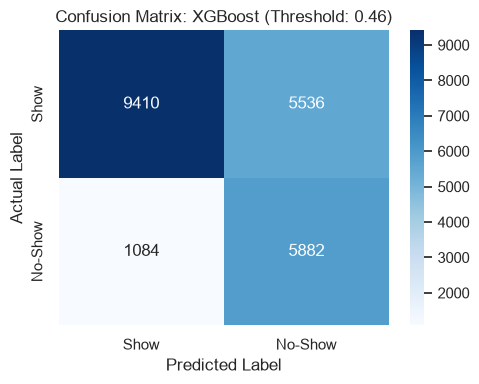

In [5]:
best_meta = results[best_model_name]
cm = np.array(best_meta['confusion_matrix_tuned'])

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Show', 'No-Show'], yticklabels=['Show', 'No-Show'])
plt.title(f'Confusion Matrix: {best_model_name} (Threshold: {best_meta["optimal_threshold"]:.2f})')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()


### 4. Feature Importance & Interpretation

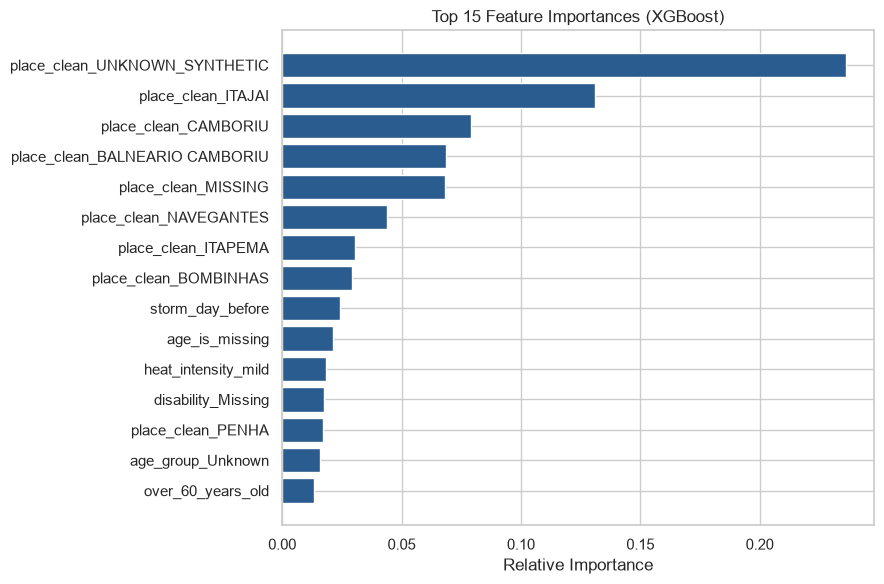

In [6]:
feat_imp = extract_feature_importance(best_pipeline)

plt.figure(figsize=(9, 6))
top15 = feat_imp.head(15).iloc[::-1]
plt.barh(top15['feature'], top15['importance'], color='#2b5c8f')
plt.title(f'Top 15 Feature Importances ({best_model_name})')
plt.xlabel('Relative Importance')
plt.tight_layout()
plt.show()


### 5. Save Model Artifact

Artifacts are written only by run_pipeline.py